# 01 - Bisection: state of charge from open-circuit voltage

**Goal.** Implement bisection from scratch and study how fast it converges.

**Problem (my own).** A battery cell's open-circuit voltage (OCV) depends on its state of charge $z \in [0, 1]$. Given a measured OCV, find $z$. The model below is *illustrative*, not a fitted cell model:

$$\mathrm{OCV}(z) = 3.0 + 1.0\,z + 0.2\,z^2 - 0.4\,e^{-30 z}$$

OCV rises monotonically from 2.6 V to 4.2 V, so $f(z) = \mathrm{OCV}(z) - v_{\text{meas}}$ has exactly one root in $[0, 1]$ whenever $v_{\text{meas}}$ is in that range.

In [1]:
import sys
sys.path.insert(0, "../src")  # lets this notebook run without installing the package

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (6.5, 3.6), "axes.grid": True})
from scipy.optimize import bisect, brentq

from nummeth import bisection

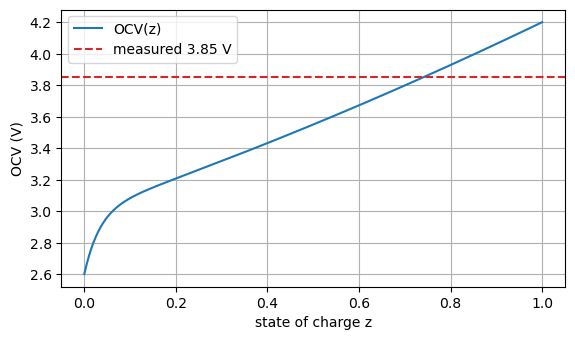

In [2]:
def ocv(z):
    return 3.0 + 1.0 * z + 0.2 * z**2 - 0.4 * np.exp(-30.0 * z)

V_MEAS = 3.85  # volts, a made-up measurement

def f(z):
    return ocv(z) - V_MEAS

z = np.linspace(0, 1, 400)
plt.plot(z, ocv(z), label="OCV(z)")
plt.axhline(V_MEAS, color="tab:red", ls="--", label=f"measured {V_MEAS} V")
plt.xlabel("state of charge z"); plt.ylabel("OCV (V)"); plt.legend(); plt.show()

## Method

Bisection keeps an interval $[a, b]$ with $f(a)$ and $f(b)$ of opposite signs, evaluates $f$ at the midpoint, and keeps the half that still contains the sign change. The interval halves every iteration, so the error is bounded by $(b - a)/2^k$ after $k$ steps.

In [3]:
result = bisection(f, 0.0, 1.0, tol=1e-8)
print(f"root       = {result.root:.10f}")
print(f"iterations = {result.iterations}")
print(f"|f(root)|  = {result.residual:.2e}")
print(f"converged  = {result.converged}")

root       = 0.7403703555
iterations = 27
|f(root)|  = 8.13e-09
converged  = True


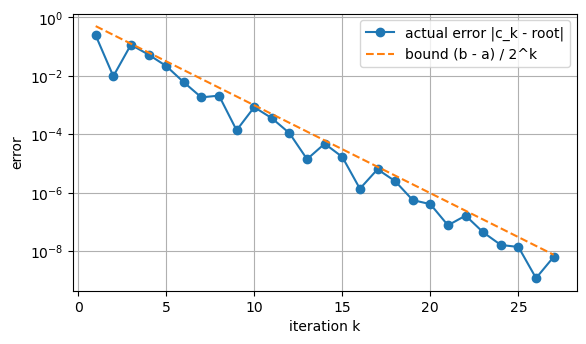

In [4]:
ref = brentq(f, 0.0, 1.0, xtol=1e-15)           # independent reference root
errors = [abs(c - ref) for c in result.history]
bounds = [1.0 / 2**k for k in range(1, len(errors) + 1)]  # (b - a) / 2^k with b - a = 1

plt.semilogy(range(1, len(errors) + 1), errors, "o-", label="actual error |c_k - root|")
plt.semilogy(range(1, len(errors) + 1), bounds, "--", label="bound (b - a) / 2^k")
plt.xlabel("iteration k"); plt.ylabel("error"); plt.legend(); plt.show()

In [5]:
import math

print(f"{'tol':>8} {'iterations':>11} {'ceil(log2((b-a)/tol))':>24}")
for tol in [1e-2, 1e-4, 1e-6, 1e-8, 1e-10, 1e-12]:
    r = bisection(f, 0.0, 1.0, tol=tol)
    print(f"{tol:>8.0e} {r.iterations:>11d} {math.ceil(math.log2(1.0 / tol)):>24d}")

     tol  iterations    ceil(log2((b-a)/tol))
   1e-02           7                        7
   1e-04          14                       14
   1e-06          20                       20
   1e-08          27                       27
   1e-10          34                       34
   1e-12          40                       40


In [6]:
# Cross-check against SciPy (iteration counts differ because stopping rules differ).
root_b, info_b = bisect(f, 0.0, 1.0, xtol=1e-8, full_output=True)
root_q, info_q = brentq(f, 0.0, 1.0, xtol=1e-8, full_output=True)
print(f"mine     : root = {result.root:.10f}, iterations = {result.iterations}")
print(f"bisect   : root = {root_b:.10f}, iterations = {info_b.iterations}")
print(f"brentq   : root = {root_q:.10f}, iterations = {info_q.iterations}")

mine     : root = 0.7403703555, iterations = 27
bisect   : root = 0.7403703555, iterations = 27
brentq   : root = 0.7403703493, iterations = 7


In [7]:
# What happens when the interval does not bracket a root? A measurement of 4.5 V is outside the model's range.
V_MEAS = 4.5
try:
    bisection(f, 0.0, 1.0)
except ValueError as err:
    print("ValueError:", err)
V_MEAS = 3.85  # restore

ValueError: f(a) and f(b) must have opposite signs


## Observations

- What does the error plot show compared with the bound? Is the error always below the bound?
- How does the iteration count change when `tol` is reduced by a factor of 100?
- Why does the bracket check matter? What would the method do without it?

The plot compares the actual error with the worst-case bound (b - a)/2^k. The actual error stays below the bound at every iteration, and this is a guarantee, not just a tendency. It zigzags instead of falling steadily, because a midpoint can land close to the root by luck. Both the error and the bound go to zero as the iterations increase; the error does not approach the bound.

The iteration count grows logarithmically as `tol` shrinks: n is about log2((b - a)/tol). In my table, `tol` of 1e-2, 1e-4 and 1e-6 needed 7, 14 and 20 iterations, so making `tol` 100 times smaller adds only about 6 to 7 iterations. The tolerance decides the precision of the approximation, and a smaller one costs a few more iterations.

The bracket check (f(a) and f(b) have opposite signs) guarantees, by the intermediate value theorem, that a continuous function has at least one root between the two initial guesses. Without it, bisection would still halve the interval, but its rule for choosing which half to keep no longer points to a root. For the 4.5 V measurement, where f is negative everywhere, it would keep moving toward the endpoint z = 1, where f is about -0.3, not 0. The check also cannot help if the function is not continuous, because a sign change can come from a pole instead of a root.